In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
!pip install -q datasets accelerate evaluate emoji soynlp

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.4/608.4 kB 48.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 416.8/416.8 kB 34.4 MB/s eta 0:00:00


In [3]:
import os, re, json, torch, evaluate, wandb
import pandas as pd
from transformers import AutoModelForSequenceClassification, TrainingArguments, Trainer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from torch import nn
import numpy as np
from transformers import DataCollatorWithPadding

# 데이터셋 준비
- 쇼핑몰로 사용. SNS는 너무 적음(5,000)
- 쇼핑 - 가전으로 사용 (영상, 생활, 주방가전, 계절가전)끼리의 규모가 제일 비슷함 7500~ 12000
- model_name = "beomi/KcELECTRA-base" / 기사 댓글이라서 SNS든 쇼핑몰이든 별로일ㄷ스
- 학습 데이터는 2019.01.01 ~ 2021.03.09 사이에 작성된 댓글 많은 뉴스/혹은 전체 뉴스 기사들의 댓글과 대댓글을 모두 수집한 데이터입니다.


In [4]:
# 쇼핑몰 / 화장품
# data_dir = "./review-sentiment-analysis/쇼핑몰/03. 가전"
data_dir = "/content/drive/MyDrive/03. 가전"

json_paths = []
#root 지금 방문한 폴더, _ 하위폴더, # 폴더안의 파일 이름 목록
for root, _, files in os.walk(data_dir): # 가전 아래의 모든 폴더 뒤지기
    for file in files: # 파일들 중에서
        if file.endswith(".json"): # 각 json 파일
            json_paths.append(os.path.join(root, file)) # 파일 이름 다 추가


data = []

for path in json_paths: # json 파일에서
    with open(path, 'r', encoding='utf-8') as f:
        try:
            items = json.load(f) #
            for item in items: # 한 json의 여러 리뷰에서
                polarity = item.get("GeneralPolarity", None) # str, 필수로 들어있음
                # 상품평 전체 감정 극성

                text = item.get("RawText", None) # 필수로 들어있음

#str임. "RawText": "유통기한도 넉넉하고  구성도 많아서 선물 하기 좋네요.   만족합니다.",


                text = re.sub(r'\s+', ' ', text).strip() # ㅗㅇ백 제거

                if polarity is not None and text:
                    polarity = int(polarity)
                    if polarity in [-1, 0, 1]: # -1 bad, 0 neutral, 1 good 인거 같음
                        data.append({
                            "text": text,
                            "label": polarity + 1  # -1 → 0, 0 → 1, 1 → 2
                        })
        except Exception:
            continue  # 형식 이상한 파일은 무시하고 넘어감

df = pd.DataFrame(data)
print(df["label"].value_counts())
df = df.dropna().drop_duplicates() # 필수 여부:Y 로 들어있어서 아마 없을듯
print(df["label"].value_counts())

label
2    22703
1     9509
0     3541
Name: count, dtype: int64
label
2    22703
1     9509
0     3541
Name: count, dtype: int64


# label 분포 확인
- 0이 매우 적음, 불균형적이긴 함. 음... stratified로 나눠고... confusion matrix 전부 다 확인하기
- 2번 65퍼,  1번 25퍼,  0번 10퍼 정도
```Text
label
2    22703
1     9509
0     3541
```

# 전처리
- 아래 명령어로 pip로 설치한 뒤, 아래 clean함수로 클리닝을 하면 Downstream task에서 보다 성능이 좋아집니다. ([UNK] 감소)https://huggingface.co/beomi/KcELECTRA-base

In [5]:
import re
import emoji
from soynlp.normalizer import repeat_normalize

# url 없애기
url_pattern = re.compile(
    r'https?:\/\/(www\.)?[-a-zA-Z0-9@:%._\+~#=]{1,256}\.[a-zA-Z0-9()]{1,6}\b([-a-zA-Z0-9()@:%_\+.~#?&//=]*)'
)

def clean(x):
    x = url_pattern.sub('', x)

    # 반복 문자 축약 (ㅋㅋㅋㅋㅋ -> ㅋㅋ)
    x = repeat_normalize(x, num_repeats=2)

    # 아까함
    # x = re.sub(r'\s+', ' ', x).strip()

    return x

# 적용
df['text'] = df['text'].apply(clean)

# Train_Test_Split

In [6]:
from datasets import Dataset

dataset = Dataset.from_pandas(df)

dataset = dataset.class_encode_column("label")
dataset = dataset.train_test_split(test_size=0.2, seed=42, stratify_by_column="label")
dataset
# 총 35,753개

Stringifying the column:   0%|          | 0/35753 [00:00<?, ? examples/s]

Casting to class labels:   0%|          | 0/35753 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 28602
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7151
    })
})

# dataset 분포 시각화
- 비율 비슷함

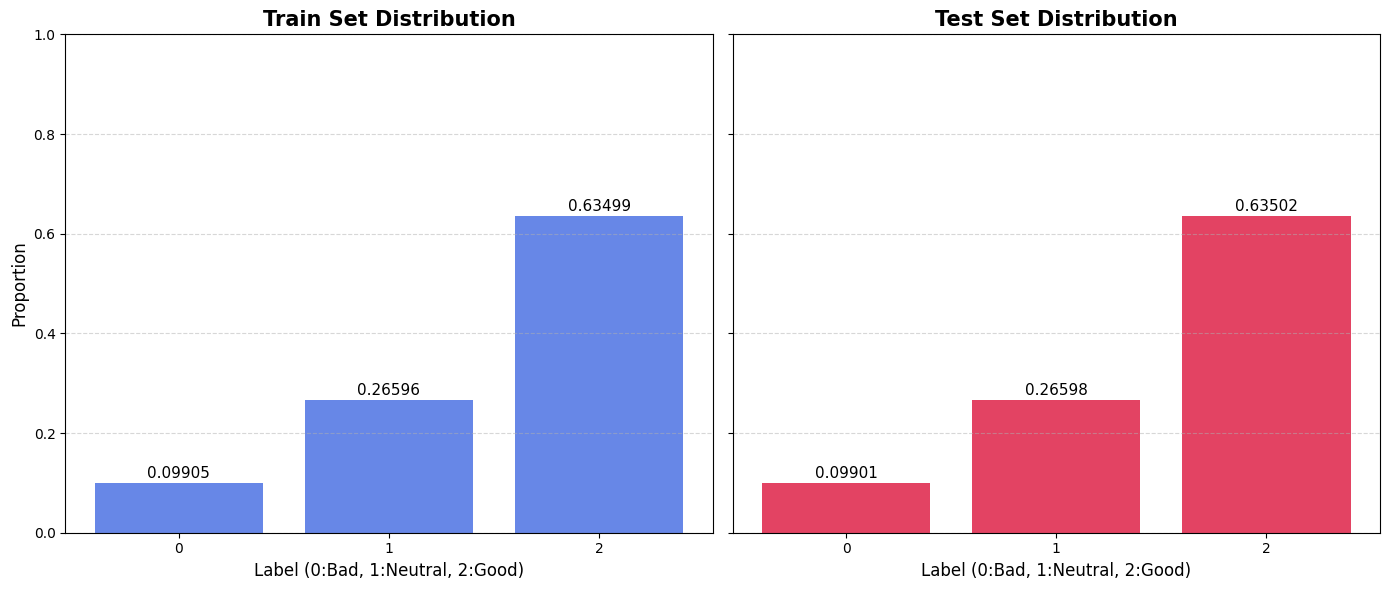

In [7]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. 데이터 준비 (비율 계산 및 인덱스 정렬 0,1,2)
train_probs = pd.Series(dataset['train']['label']).value_counts(normalize=True).sort_index()
test_probs = pd.Series(dataset['test']['label']).value_counts(normalize=True).sort_index()

# 2. 그래프 그리기 (1행 2열)
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True) # sharey=True: Y축 눈금 통일

# --- 왼쪽: Train Set (파란색) ---
bars1 = axes[0].bar(train_probs.index, train_probs.values, color='royalblue', alpha=0.8)
axes[0].set_title('Train Set Distribution', fontsize=15, fontweight='bold')
axes[0].set_xlabel('Label (0:Bad, 1:Neutral, 2:Good)', fontsize=12)
axes[0].set_ylabel('Proportion', fontsize=12)
axes[0].set_xticks([0, 1, 2])
axes[0].set_ylim(0, 1.0) # Y축을 0~1로 고정
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# 값 표시 (막대 위에 숫자 쓰기)
for bar in bars1:
    height = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, height + 0.01, f'{height:.5f}', ha='center', fontsize=11)

# --- 오른쪽: Test Set (빨간색) ---
bars2 = axes[1].bar(test_probs.index, test_probs.values, color='crimson', alpha=0.8)
axes[1].set_title('Test Set Distribution', fontsize=15, fontweight='bold')
axes[1].set_xlabel('Label (0:Bad, 1:Neutral, 2:Good)', fontsize=12)
axes[1].set_xticks([0, 1, 2])
axes[1].set_ylim(0, 1.0)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

# 값 표시
for bar in bars2:
    height = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, height + 0.01, f'{height:.5f}', ha='center', fontsize=11)

plt.tight_layout()
plt.show()

# Max_len 구하기
``` text
95% 75개
98% 88개
99.5% 120개
100% 230개
```
#### 128개로 잡으면 될듯
##### Train, Test 모두
``` text
label = 0은 2% 미만 손실
label = 1은 1% 미만 손실
label = 2은 1% 미만 손실
```

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/288 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/514 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

[Train] 분석 시작...

=== Train 상세 분석 결과 ===
상위 99.5% 길이 기준: 115.0 토큰
----------------------------------------
Label      전체 개수      손실 개수      손실 비율(%)  
----------------------------------------
0          2833       38         1.34      
1          7607       34         0.45      
2          18162      67         0.37      
----------------------------------------
[Test] 분석 시작...

=== Test 상세 분석 결과 ===
상위 99.5% 길이 기준: 120.2 토큰
----------------------------------------
Label      전체 개수      손실 개수      손실 비율(%)  
----------------------------------------
0          708        8          1.13      
1          1902       9          0.47      
2          4541       19         0.42      
----------------------------------------


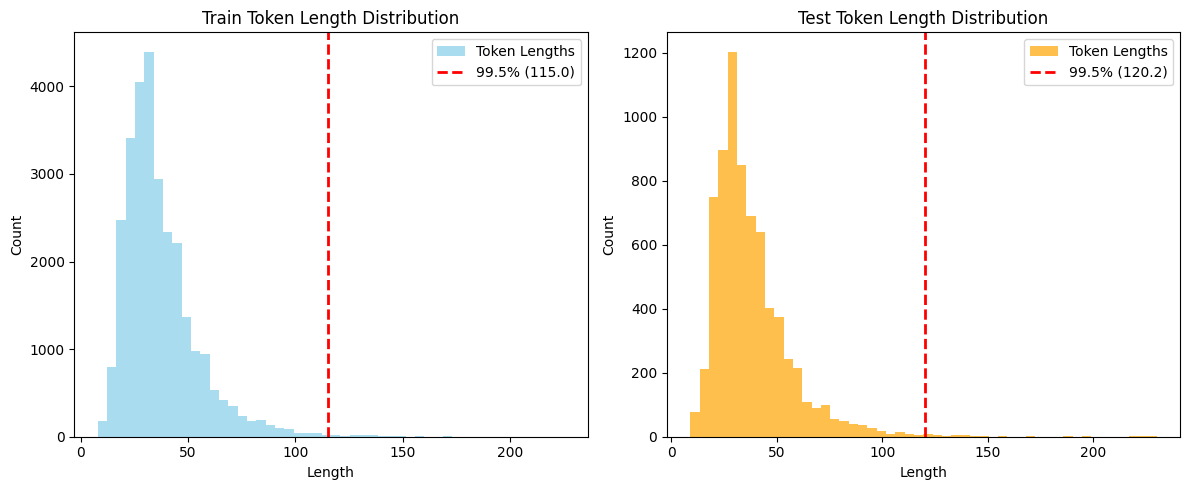

In [10]:
import matplotlib.pyplot as plt
from transformers import AutoTokenizer
from collections import Counter
model_name = "beomi/KcELECTRA-base"
# 학습 데이터는 2019.01.01 ~ 2021.03.09 사이에 작성된 댓글 많은 뉴스/혹은 전체 뉴스 기사들의 댓글과 대댓글을 모두 수집한 데이터입니다.

tokenizer = AutoTokenizer.from_pretrained(model_name)

def analyze_token_lengths_by_label(dataset_split, split_name, tokenizer):
    print(f"[{split_name}] 분석 시작...")

    # 데이터 저장용 리스트
    lengths = []
    labels = []

    # 데이터 순회하며 길이와 라벨 수집
    for item in dataset_split:
        lengths.append(len(tokenizer.encode(item["text"])))
        labels.append(item["label"])

    # 99.5% 기준 계산
    percentile_95 = np.percentile(lengths, 99.5)

    # 손실된 데이터의 라벨 카운트
    truncated_labels = []
    for length, label in zip(lengths, labels):
        if length > percentile_95:
            truncated_labels.append(label)

    truncated_counts = Counter(truncated_labels)
    total_counts = Counter(labels)

    print(f"\n=== {split_name} 상세 분석 결과 ===")
    print(f"상위 99.5% 길이 기준: {percentile_95:.1f} 토큰")
    print("-" * 40)
    print(f"{'Label':<10} {'전체 개수':<10} {'손실 개수':<10} {'손실 비율(%)':<10}")
    print("-" * 40)

    # 라벨별 통계 출력 (0, 1, 2 순서대로)
    for label_id in sorted(total_counts.keys()):
        total = total_counts[label_id]
        loss = truncated_counts[label_id]
        ratio = (loss / total) * 100 if total > 0 else 0
        print(f"{label_id:<10} {total:<10} {loss:<10} {ratio:<10.2f}")
    print("-" * 40)

    return lengths, percentile_95

# Train과 Test 데이터 분석 실행
train_lengths, train_95 = analyze_token_lengths_by_label(dataset["train"], "Train", tokenizer)
test_lengths, test_95 = analyze_token_lengths_by_label(dataset["test"], "Test", tokenizer)

# 그래프 그리기 (기존과 동일)
plt.figure(figsize=(12, 5))

# Train 그래프
plt.subplot(1, 2, 1)
plt.hist(train_lengths, bins=50, color='skyblue', alpha=0.7, label='Token Lengths')
plt.axvline(train_95, color='red', linestyle='dashed', linewidth=2, label=f'99.5% ({train_95:.1f})')
plt.title(f'Train Token Length Distribution')
plt.xlabel('Length')
plt.ylabel('Count')
plt.legend()

# Test 그래프
plt.subplot(1, 2, 2)
plt.hist(test_lengths, bins=50, color='orange', alpha=0.7, label='Token Lengths')
plt.axvline(test_95, color='red', linestyle='dashed', linewidth=2, label=f'99.5% ({test_95:.1f})')
plt.title(f'Test Token Length Distribution')
plt.xlabel('Length')
plt.ylabel('Count')
plt.legend()

plt.tight_layout()
plt.show()

# 토큰화
 - https://huggingface.co/beomi/KcELECTRA-base

In [11]:


model_name = "beomi/KcELECTRA-base"
# 학습 데이터는 2019.01.01 ~ 2021.03.09 사이에 작성된 댓글 많은 뉴스/혹은 전체 뉴스 기사들의 댓글과 대댓글을 모두 수집한 데이터입니다.

tokenizer = AutoTokenizer.from_pretrained(model_name)


def preprocess(example):
    tokenized = tokenizer(
        example["text"],
        truncation=True,
        padding=True, # longest
        max_length=128
    )
    tokenized["text"] = example["text"]
    return tokenized


tokenized_dataset = dataset.map(preprocess, batched=True)
tokenized_dataset = tokenized_dataset.rename_column("label", "labels")
tokenized_dataset.set_format(
    type="torch",
    columns=["text", "input_ids", "attention_mask", "labels"],
)
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
tokenized_dataset # token_type_ids X

Map:   0%|          | 0/28602 [00:00<?, ? examples/s]

Map:   0%|          | 0/7151 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 28602
    })
    test: Dataset({
        features: ['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 7151
    })
})

# Full Fine-Tuning
- 너무 과적합이됨
- L4 기준으로 25분동안 진행됨

In [14]:
import torch
from torch import nn
from transformers import Trainer

In [18]:
wandb.init(project="PEFT")

class_counts = [3541, 9509, 22703]
total = sum(class_counts)
weights = [total / (3 * c) for c in class_counts]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
class_weights = torch.tensor(weights).float().to(device)

print(f"Class Weights: {class_weights}") # 가중치 확인용

class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")

        loss_fct = nn.CrossEntropyLoss(weight=class_weights)
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))

        return (loss, outputs) if return_outputs else loss

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)

    acc = accuracy_score(labels, preds)


    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, preds, average='weighted'
    )

    return {
        "accuracy": acc,
        "f1": f1,
        "precision": precision,
        "recall": recall
    }

num_epochs = 5
batch_size = 64
training_args = TrainingArguments(
    output_dir="./results",
    eval_strategy="epoch",
    save_strategy = "epoch",
    load_best_model_at_end=True,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    num_train_epochs=num_epochs,
    report_to="wandb",
)

# model_name = "beomi/KcELECTRA-base"
model_ft = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=3)
model_ft.to(device)


trainer_ft = WeightedTrainer(
    model=model_ft,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["test"],
    compute_metrics=compute_metrics,
    data_collator=data_collator,
)

trainer_ft.train()
wandb.finish()

Class Weights: tensor([3.3656, 1.2533, 0.5249], device='cuda:0')


Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at beomi/KcELECTRA-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,No log,0.257056,0.911481,0.913230,0.917212,0.911481
2,0.347200,0.280366,0.909104,0.910273,0.913096,0.909104
3,0.192300,0.385758,0.918892,0.919495,0.920850,0.918892
4,0.115600,0.462972,0.917634,0.918070,0.919212,0.917634
5,0.065100,0.506119,0.917494,0.918341,0.920282,0.917494


eval/accuracy,▃▁█▇▇
eval/f1,▃▁█▇▇
eval/loss,▁▂▅▇█
eval/precision,▅▁█▇▇
eval/recall,▃▁█▇▇
eval/runtime,▆█▁▅▂
eval/samples_per_second,▃▁█▄▇
eval/steps_per_second,▃▁█▃█
train/epoch,▁▁▃▃▅▅▆▇██
train/global_step,▁▁▃▃▅▅▆▇██
+3,...


# 파인 튜닝 모델 저장
- zip 파일 기준으로 **405.5MB**

In [19]:
import shutil
from google.colab import files

def save_and_download_model(trainer, tokenizer, model_path):
    trainer.save_model(model_path)
    tokenizer.save_pretrained(model_path)

    shutil.make_archive(model_path, "zip", model_path)
    files.download(f"{model_path}.zip")


save_and_download_model(trainer_ft, tokenizer, "full_finetuning")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 파인튜닝 측정 결과
- 실제 부정 -> 예측 중립을 가장 많이 틀림
- 실제 중립 -> 예측 부정, 긍정 반반
- 실제 긍정 -> 예측 긍정
- **부정을 긍정으로, 긍정을 부정으로 예측하는 경우는 거의 없음**

In [24]:
wandb.init()
def get_predictions_and_labels(trainer, dataset):
    predictions = trainer.predict(dataset)
    pred_labels = torch.argmax(torch.tensor(predictions.predictions), dim=1)
    true_labels = predictions.label_ids

    return pred_labels, true_labels


pred_labels, true_labels = get_predictions_and_labels(trainer_ft, tokenized_dataset["test"])

🎯 테스트 정확도: 91.15%


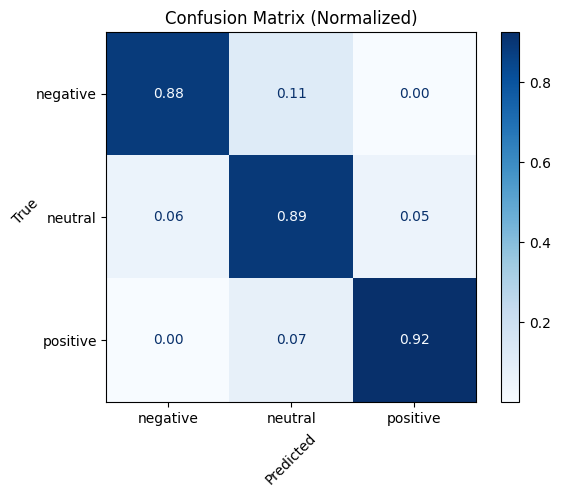

In [25]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

def print_acc_and_confusion_matrix(true_labels, pred_labels):
    test_accuracy = accuracy_score(true_labels, pred_labels)
    print(f"🎯 테스트 정확도: {test_accuracy * 100:.2f}%")


    # nor : 합이 1이되도록
    cm = confusion_matrix(true_labels, pred_labels, normalize='true')

    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["negative", "neutral", "positive"])

    disp.plot(cmap="Blues", values_format='.2f') # 둘째자리까지
    plt.title("Confusion Matrix (Normalized)")
    plt.xlabel("Predicted", rotation=45)
    plt.ylabel("True", rotation=45)

    plt.show()

print_acc_and_confusion_matrix(true_labels, pred_labels)

In [28]:
def print_samples(dataset, true_labels, pred_labels, num_samples=5):
    label_to_text = {0: "negative", 1: "neutral", 2: "positive"}

    # 정답/예측 샘플 출력
    print("\n✅ 예측 결과 샘플:")
    for i in range(num_samples):
        print("📝 원문:", dataset[i]["text"])
        print("✅ 실제:", label_to_text[dataset[i]["label"]], "🔮 예측:", label_to_text[pred_labels[i].item()])
        print("-" * 40)

    # 오분류된 샘플 출력
    print("\n\n❌ 예측이 틀린 샘플:")
    wrong_indices = [i for i, (pred, true) in enumerate(zip(pred_labels, true_labels)) if pred != true]
    for i in wrong_indices[:num_samples]:
        print("📝 원문:", dataset[i]["text"])
        print("✅ 실제:", label_to_text[dataset[i]["label"]], "🔮 예측:", label_to_text[pred_labels[i].item()])
        print("-" * 40)


num_samples = 5
print_samples(dataset["test"], true_labels, pred_labels, num_samples)


✅ 예측 결과 샘플:
📝 원문: 온풍기 사이즈가 작아서 맘에 들어요. 본체 발열감이 없고 안전해서 어린아이 있는 가정에서 사용하기 좋아요.
✅ 실제: positive 🔮 예측: positive
----------------------------------------
📝 원문: 집 안에 설치했는데 색상이 워낙 예뻐서 인테리어와 찰떡이네요~! 하지만 사용하니 생기는 발열감은 약간 아쉽군요,,
✅ 실제: neutral 🔮 예측: neutral
----------------------------------------
📝 원문: 음량이 크고 선명하니 성능이 대단 한것같아서 만족합니다. 디자인도 깔끔하니 거실이 한결 더 깔끔해져보여서 좋아요
✅ 실제: positive 🔮 예측: positive
----------------------------------------
📝 원문: 무게가 가벼워서 좌식테이블에 간단히 올려두기에 좋네요 노트북 전송도 가능한 점이 편리해서 좋아요 어디에서든 바로바로 시청할수 있는 점이 좋습니다. ^^
✅ 실제: positive 🔮 예측: positive
----------------------------------------
📝 원문: 000 청소기 너무 좋습니다 힘도쎄고 디자인도 이쁘고요
✅ 실제: positive 🔮 예측: positive
----------------------------------------


❌ 예측이 틀린 샘플:
📝 원문: 가격은 좀 비싸도 제품 디자인은 깔끔하고 360도 회전되는 기능적 장점과 저속일때 조용한 장점이라 생각했는데 아무일도 없었는데 선풍기 하나가 위아래로 도는 회전이 되질 않아요 ㅠㅠ이문제를 어떻게 해야할지 문의를 일단 해보려 합니다.
✅ 실제: neutral 🔮 예측: negative
----------------------------------------
📝 원문: 요즘 인버터 시스템이 대세라길라 구매했는데 역시 전기세 걱정은 없네요. 근데 생각보다 정말 작동시 소음이 굉장히 크고 알림음도 시끄러

# PEFT

In [36]:
from peft import get_peft_model, LoraConfig, TaskType

peft_config = LoraConfig(
    task_type=TaskType.SEQ_CLS, # 문장 분류
    inference_mode=False,
    r=8, # 표현력
    lora_alpha=16, # 강도
    lora_dropout=0.1,
)

model_peft = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=3)
model_peft = get_peft_model(model_peft, peft_config)
model_peft.print_trainable_parameters() # 얼만큼 변할지

Some weights of ElectraForSequenceClassification were not initialized from the model checkpoint at beomi/KcELECTRA-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


trainable params: 887,811 || all params: 109,971,462 || trainable%: 0.8073


In [ ]:
wandb.init(project="PEFT", name="LoRA_1")

num_epochs = 5
batch_size = 64
training_args_peft = TrainingArguments(
    output_dir="./results_peft",
    eval_strategy="epoch",       # 평가 주기
    save_strategy="epoch",       # 저장 주기
    load_best_model_at_end=True,
    metric_for_best_model="accuracy", # 정확도로 하는 게 맞나음..., f1이 나았을듯.
    save_total_limit=1,
    per_device_train_batch_size=batch_size,
    per_device_eval_batch_size=batch_size,
    num_train_epochs=num_epochs,
    report_to="wandb",
)

trainer_peft = WeightedTrainer(
    model=model_peft,
    args=training_args_peft,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["test"],
    compute_metrics=compute_metrics,
    data_collator=data_collator,
)
trainer_peft.train()
wandb.finish()

eval/accuracy,▁
eval/f1,▁
eval/loss,▁
eval/precision,▁
eval/recall,▁
eval/runtime,▁
eval/samples_per_second,▁
eval/steps_per_second,▁
train/epoch,▁█
train/global_step,▁█
+3,...


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,No log,0.313010,0.891763,0.893875,0.899018,0.891763
2,0.304000,0.332372,0.902531,0.902902,0.903474,0.902531
3,0.284000,0.330263,0.904769,0.905300,0.906038,0.904769
4,0.266200,0.303603,0.902531,0.903764,0.905945,0.902531
5,0.265200,0.300358,0.900713,0.901925,0.904186,0.900713


eval/accuracy,▁▇█▇▆
eval/f1,▁▇█▇▆
eval/loss,▄██▂▁
eval/precision,▁▅██▆
eval/recall,▁▇█▇▆
eval/runtime,▁▇█▄▄
eval/samples_per_second,█▂▁▅▅
eval/steps_per_second,█▂▁▅▅
train/epoch,▁▁▃▃▅▅▆▇██
train/global_step,▁▁▃▃▅▅▆▇██
+3,...


In [33]:
save_and_download_model(trainer_peft, tokenizer, "peft")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 로라 측정 결과
- 파인 튜닝과 마찬가지로 예측함

🎯 테스트 정확도: 90.48%


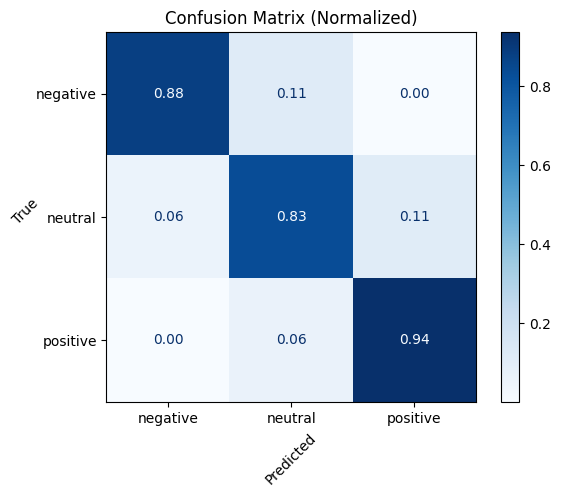


✅ 예측 결과 샘플:
📝 원문: 온풍기 사이즈가 작아서 맘에 들어요. 본체 발열감이 없고 안전해서 어린아이 있는 가정에서 사용하기 좋아요.
✅ 실제: positive 🔮 예측: positive
----------------------------------------
📝 원문: 집 안에 설치했는데 색상이 워낙 예뻐서 인테리어와 찰떡이네요~! 하지만 사용하니 생기는 발열감은 약간 아쉽군요,,
✅ 실제: neutral 🔮 예측: neutral
----------------------------------------
📝 원문: 음량이 크고 선명하니 성능이 대단 한것같아서 만족합니다. 디자인도 깔끔하니 거실이 한결 더 깔끔해져보여서 좋아요
✅ 실제: positive 🔮 예측: positive
----------------------------------------
📝 원문: 무게가 가벼워서 좌식테이블에 간단히 올려두기에 좋네요 노트북 전송도 가능한 점이 편리해서 좋아요 어디에서든 바로바로 시청할수 있는 점이 좋습니다. ^^
✅ 실제: positive 🔮 예측: positive
----------------------------------------
📝 원문: 000 청소기 너무 좋습니다 힘도쎄고 디자인도 이쁘고요
✅ 실제: positive 🔮 예측: positive
----------------------------------------


❌ 예측이 틀린 샘플:
📝 원문: 가격이 저렴해서 부담이없어요. 아쉬운점은 시간이 지나니 바람세기가 중이상에서 소음이 커지는게 신경쓰이네요.
✅ 실제: negative 🔮 예측: neutral
----------------------------------------
📝 원문: 머리카락이 많은집은 흡입력이 약해 비추천합니다~ 흡입하는곳에 머리카락이 붙어 손으로 넣어서 빼야하네요~ 용량이 원룸정도는 좋을것같아요~ 방향조절이 힘들어 무겁게 느껴집니다~ 물걸레질을 따로 안해도 되니 그건 좋네요~
✅ 실제: negative 🔮 예측: ne

In [35]:
wandb.init()
pred_labels, true_labels = get_predictions_and_labels(trainer_peft, tokenized_dataset["test"])

print_acc_and_confusion_matrix(true_labels, pred_labels)

num_samples = 5
print_samples(dataset["test"], true_labels, pred_labels, num_samples)

# 차이
- 로라가 빠르고, 용량도 적고 비용도 적음
- 결과만 보면 파인튜닝이 조금 더 좋음
- 파인튜닝은 1에폭 때랑 제일 좋은 모델이랑 별 차이 없는 걸로 봐서 이미 다 학습한 걸로 보임 -> train_loss도 매우 빠르게 감소, 워낙 단순한 태스크 + 모델이 원래 똒똑함 + 데이터가 너무 적었떤 거 같음
- 로라도 마찬가지로 1에폭 때랑 베스트 모델이랑 별 차이가 없는 걸로 보임, 랭크제한 + train_loss 상승폭을 보니 파인튜닝보다는 확실하게 학습하지 않음.



|비교 항목|Fine-Tuning|LoRA|
|:-:|:-:|:-:|
|걸린 시간|25분|16분|
|gpu 메모리|34%|30%|
|모델 용량(zip)|440MB|4MB|
|best-F1|0.9195|0.90071|
|best-recall|0.91889|0.90477|
|train_loss|0.0651|0.2652|
|eval_loss|0.50612|0.30066|
